## Loading the Data

In [13]:
from pathlib import Path
import pandas as pd

csv_path = Path("../data/raw/carrefour_ke_black_november_deals (1).csv")
print("CSV found:", csv_path.exists())

df = pd.read_csv(csv_path)
print("Rows, columns:", df.shape)
display(df.head())

CSV found: True
Rows, columns: (370, 29)


,product_id,product_name,brand,department,category,page_section,current_price_kes,original_price_kes,listed_discount_pct,actual_discount_pct,...,size_unit_std,price_per_100_units_kes,rating,review_count,stock_left,low_stock,delivery_window,delivery_type,times_featured,scraped_on
0,CFK001,Top Food Garlic Powder Jar 100g,Top Food,Food & Beverages,Pantry & Cooking,Top Deals,196.0,245.0,20,20.0,...,g,196.0,NaN,0,4.0,True,Tomorrow 9:00 AM,Express (next day),2,2026-11-11
1,CFK002,Marinex Roasters 3Pcs Set Rectange 6722,Marinex,Home & Kitchen,Kitchen & Dining,Top Deals,1699.0,2790.0,39,39.1,...,NaN,NaN,NaN,0,1.0,True,Tomorrow 9:00 AM,Express (next day),2,2026-11-11
2,CFK003,American Tourister Bricklane 80Cm Jet Black,American Tourister,Fashion & Luggage,Luggage,Top Deals,14295.0,15850.0,10,9.8,...,NaN,NaN,NaN,0,2.0,True,14-16 Nov,Scheduled,2,2026-11-11
3,CFK004,Simple Replenishing Moisturizer 125Ml,Simple,Health & Beauty,Personal Care,Top Deals,899.0,1199.0,25,25.0,...,ml,719.2,NaN,0,NaN,False,Tomorrow 9:00 AM,Express (next day),2,2026-11-11
4,CFK005,Von Fridge Varz-20Nhk 429L Sbs Black,Von,Electronics & Appliances,Large Appliances,Top Deals,103493.0,129995.0,20,20.4,...,NaN,NaN,4.5,4,1.0,True,14-16 Nov,Scheduled,2,2026-11-11


In [14]:
import sys
from pathlib import Path

print("Python:", sys.executable)
print("Notebook folder:", Path.cwd())

Python: c:\Users\User\Desktop\KERONGO'`S SHIT\carrefour_black_november\.venv\Scripts\python.exe
Notebook folder: c:\Users\User\Desktop\KERONGO'`S SHIT\carrefour_black_november\notebooks


## Counting products by department

In [15]:
# Count products per department, including any missing department labels.
dept_counts = df["department"].value_counts(dropna=False)

# Show the counts and compare their total with the number of dataset rows.
display(dept_counts.rename_axis("department").to_frame("product_count"))
print("Counted products:", dept_counts.sum())
print("Dataset rows:", len(df))

,product_count
department,
Food & Beverages,109
Home & Kitchen,95
Health & Beauty,72
Fashion & Luggage,35
Household & Baby,31
Electronics & Appliances,28


Counted products: 370
Dataset rows: 370


## Creating the discounted-products subset

In [16]:
# Keep only rows marked as discounted.
disc = df.loc[df["is_discounted"].eq(True)].copy()

# Check the subset size and preview key price and discount fields.
print("Discounted products:", len(disc))
display(
    disc[
        [
            "product_name",
            "current_price_kes",
            "original_price_kes",
            "actual_discount_pct",
            "savings_kes",
        ]
    ].head()
)

Discounted products: 314


,product_name,current_price_kes,original_price_kes,actual_discount_pct,savings_kes
0,Top Food Garlic Powder Jar 100g,196.0,245.0,20.0,49.0
1,Marinex Roasters 3Pcs Set Rectange 6722,1699.0,2790.0,39.1,1091.0
2,American Tourister Bricklane 80Cm Jet Black,14295.0,15850.0,9.8,1555.0
3,Simple Replenishing Moisturizer 125Ml,899.0,1199.0,25.0,300.0
4,Von Fridge Varz-20Nhk 429L Sbs Black,103493.0,129995.0,20.4,26502.0


## 1st Chart

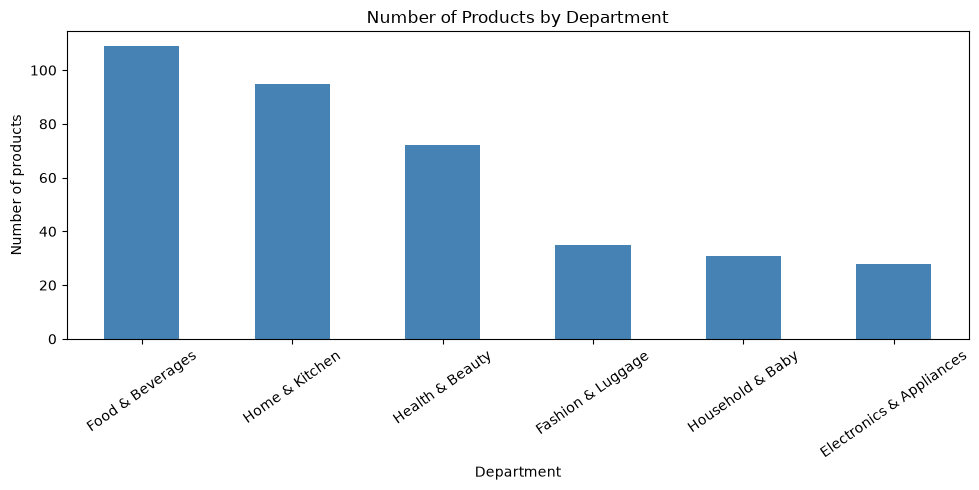

In [17]:
import matplotlib.pyplot as plt

# Count products in each department.
department_counts = df["department"].value_counts()

# Draw and label a bar chart of those counts.
fig, ax = plt.subplots(figsize=(10, 5))
department_counts.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Number of Products by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Number of products")
ax.tick_params(axis="x", rotation=35)

# Adjust spacing so department labels remain readable.
plt.tight_layout()
plt.show()

## Recreating the chart with Seaborn

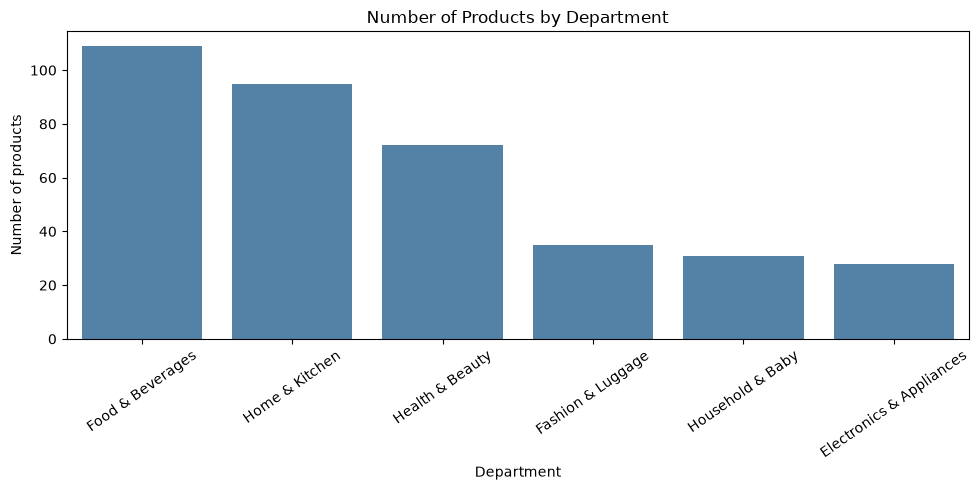

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep the departments in highest-to-lowest count order.
department_order = df["department"].value_counts().index

# Draw and label a Seaborn count plot.
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, x="department", order=department_order, color="steelblue", ax=ax)
ax.set_title("Number of Products by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Number of products")
ax.tick_params(axis="x", labelrotation=35)

# Adjust spacing for readable department labels.
plt.tight_layout()
plt.show()

## Compare average discount by department

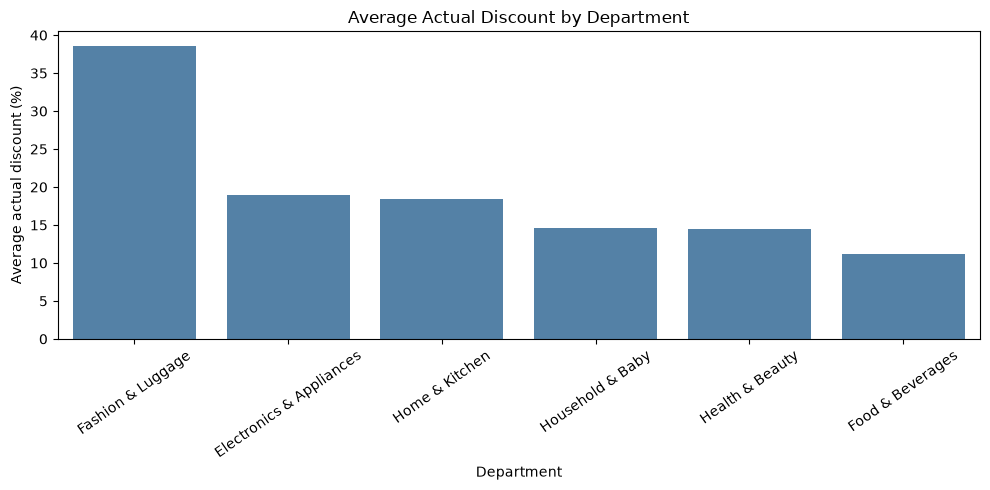

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Order departments by their average actual discount, highest first.
discount_order = (
    df.groupby("department")["actual_discount_pct"]
      .mean()
      .sort_values(ascending=False)
      .index
)

# Plot the mean actual discount percentage for each department.
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=df,
    x="department",
    y="actual_discount_pct",
    order=discount_order,
    errorbar=None,
    color="steelblue",
    ax=ax,
)
ax.set_title("Average Actual Discount by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Average actual discount (%)")
ax.tick_params(axis="x", labelrotation=35)

# Improve spacing so the department names stay readable.
plt.tight_layout()
plt.show()

## Count products by delivery type

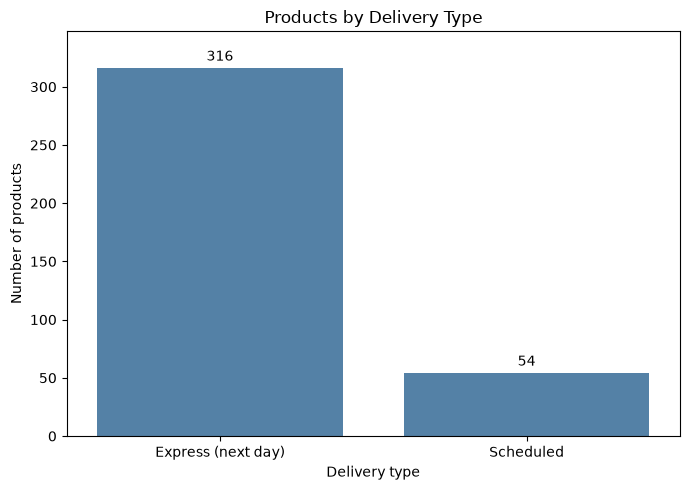

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Put the more common delivery type first.
delivery_order = df["delivery_type"].value_counts().index

# Draw a count plot and label each bar with its count.
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x="delivery_type", order=delivery_order, color="steelblue", ax=ax)
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.set_title("Products by Delivery Type")
ax.set_xlabel("Delivery type")
ax.set_ylabel("Number of products")
ax.margins(y=0.1)

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

## Compare delivery types by department

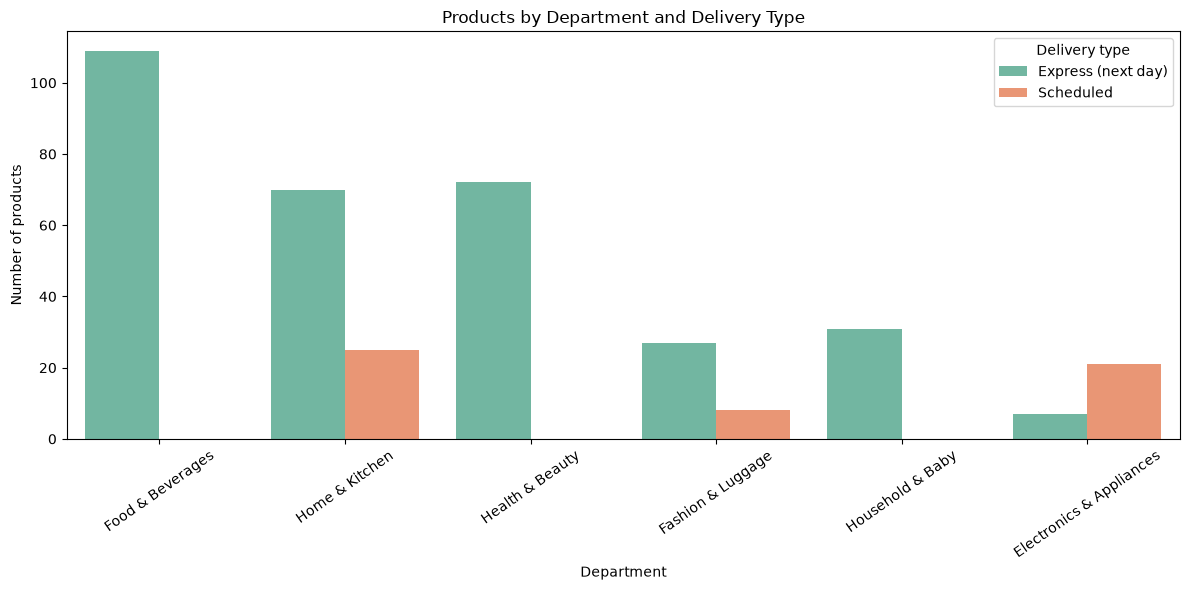

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Order departments by total product count.
department_order = df["department"].value_counts().index

# Compare product counts for each delivery type within each department.
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(
    data=df,
    x="department",
    hue="delivery_type",
    order=department_order,
    palette="Set2",
    ax=ax,
)
ax.set_title("Products by Department and Delivery Type")
ax.set_xlabel("Department")
ax.set_ylabel("Number of products")
ax.tick_params(axis="x", labelrotation=35)
ax.legend(title="Delivery type")

# Adjust spacing so department labels remain readable.
plt.tight_layout()
plt.show()

## Count products by category

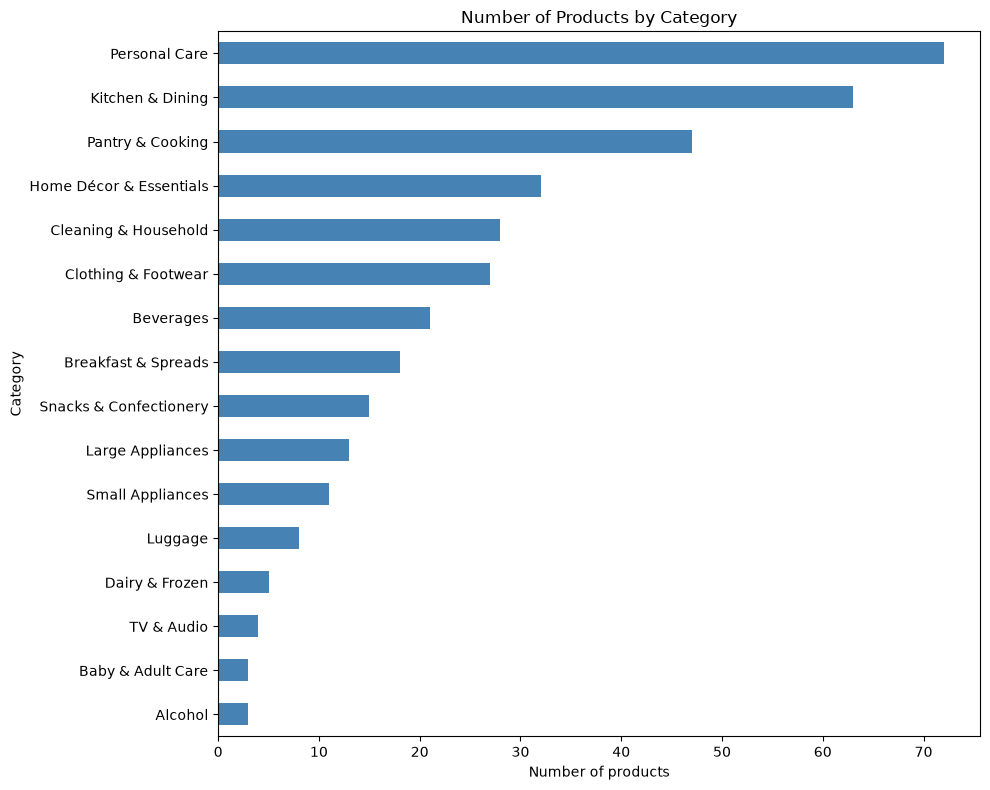

In [22]:
import matplotlib.pyplot as plt

# Count products by category and sort from fewest to most.
category_counts = df["category"].value_counts().sort_values()

# Draw horizontal bars so the largest category appears at the top.
fig, ax = plt.subplots(figsize=(10, 8))
category_counts.plot(kind="barh", color="steelblue", ax=ax)
ax.set_title("Number of Products by Category")
ax.set_xlabel("Number of products")
ax.set_ylabel("Category")

# Give the category labels enough space.
plt.tight_layout()
plt.show()

## Finding  the ten most represented brands

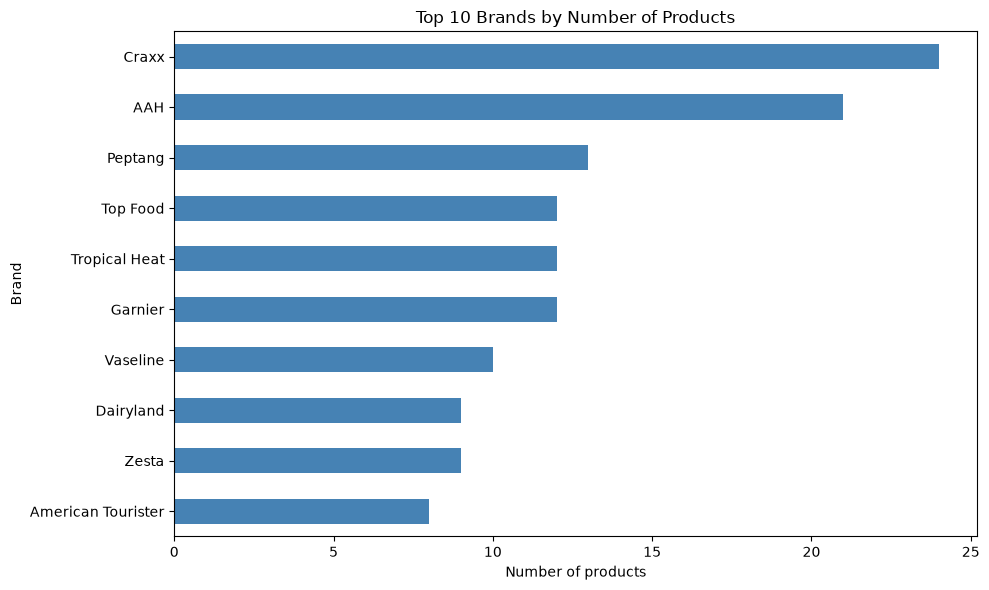

In [23]:
import matplotlib.pyplot as plt

# Select the ten brands with the most products, then sort for the chart.
top_brands = df["brand"].value_counts().head(10).sort_values()

# Draw a horizontal bar chart of those brand counts.
fig, ax = plt.subplots(figsize=(10, 6))
top_brands.plot(kind="barh", color="steelblue", ax=ax)
ax.set_title("Top 10 Brands by Number of Products")
ax.set_xlabel("Number of products")
ax.set_ylabel("Brand")

# Keep the chart labels visible.
plt.tight_layout()
plt.show()

## Chart the ten most expensive products

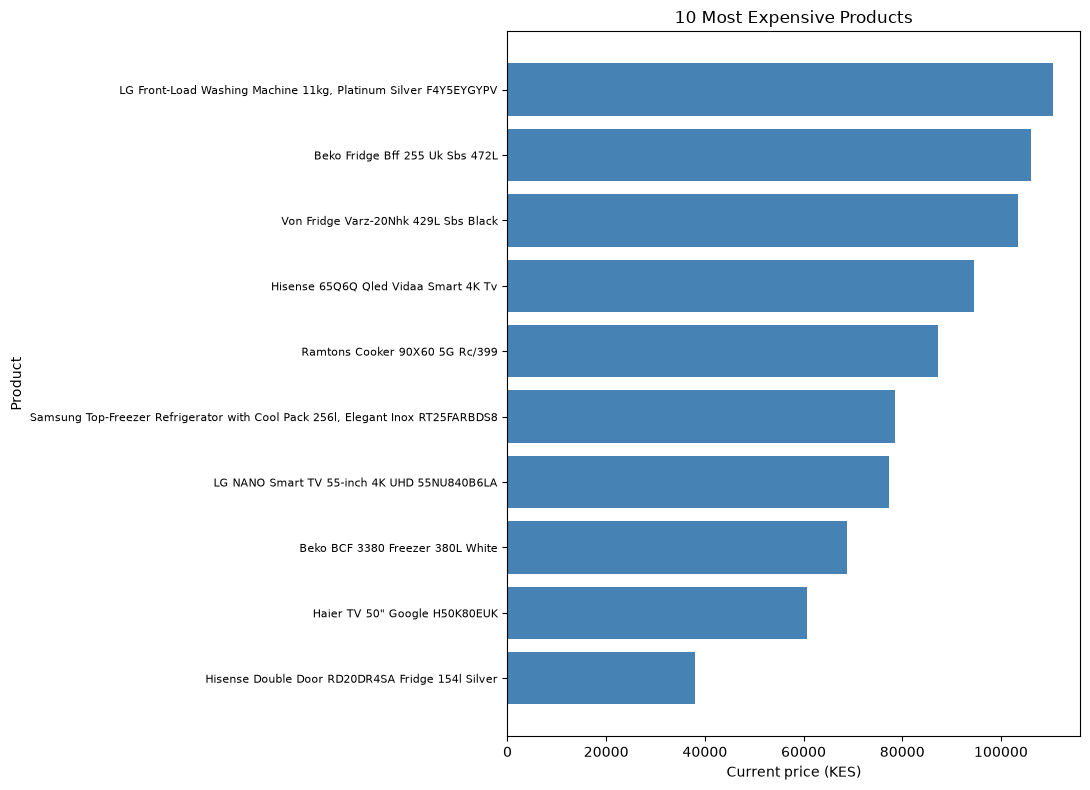

In [24]:
import matplotlib.pyplot as plt

# Select the ten highest-priced products and sort them for the chart.
top_expensive = (
    df.nlargest(10, "current_price_kes")
      .sort_values("current_price_kes")
)

# Draw horizontal bars with product names and prices in KES.
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(
    top_expensive["product_name"],
    top_expensive["current_price_kes"],
    color="steelblue",
)
ax.set_title("10 Most Expensive Products")
ax.set_xlabel("Current price (KES)")
ax.set_ylabel("Product")
ax.tick_params(axis="y", labelsize=8)

# Keep the long product names readable.
plt.tight_layout()
plt.show()

## Rank products by KES savings

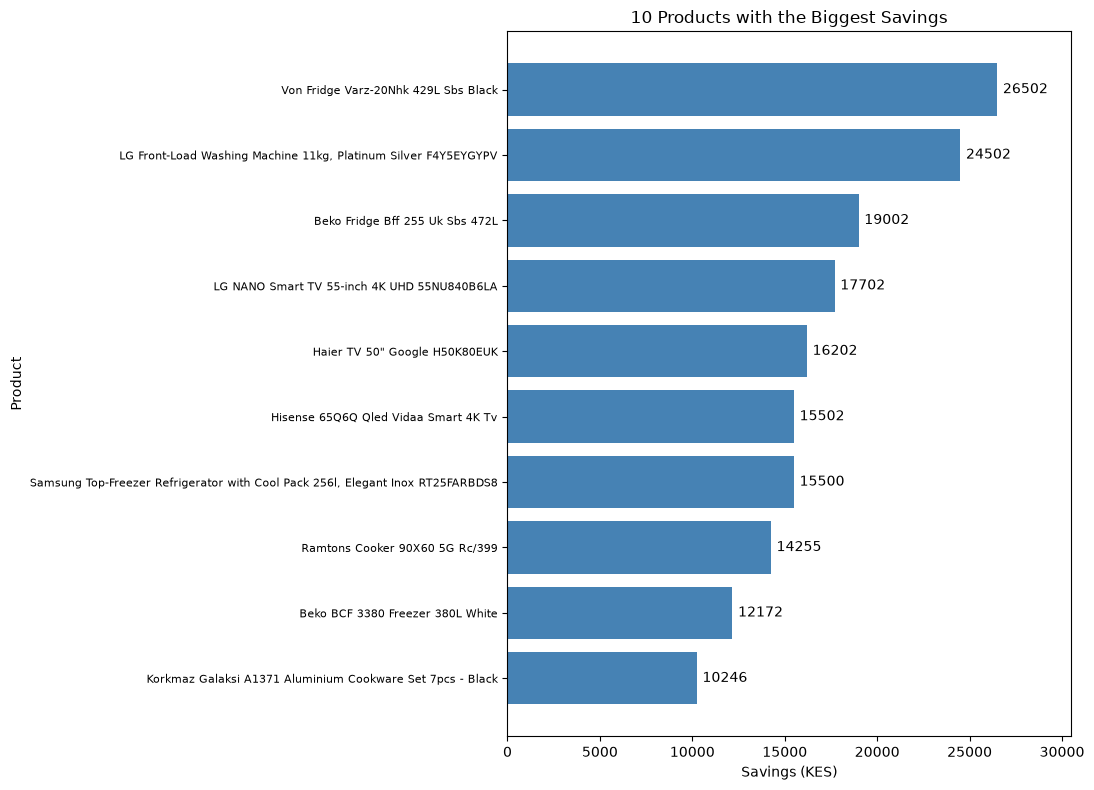

In [25]:
import matplotlib.pyplot as plt

# Select the ten products with the largest savings and sort for the chart.
top_savings = (
    df.nlargest(10, "savings_kes")
      .sort_values("savings_kes")
)

# Draw horizontal bars for savings in KES.
fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(
    top_savings["product_name"],
    top_savings["savings_kes"],
    color="steelblue",
)
ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set_title("10 Products with the Biggest Savings")
ax.set_xlabel("Savings (KES)")
ax.set_ylabel("Product")
ax.tick_params(axis="y", labelsize=8)
ax.margins(x=0.15)

# Keep labels and savings amounts visible.
plt.tight_layout()
plt.show()


## Compare median prices by page section

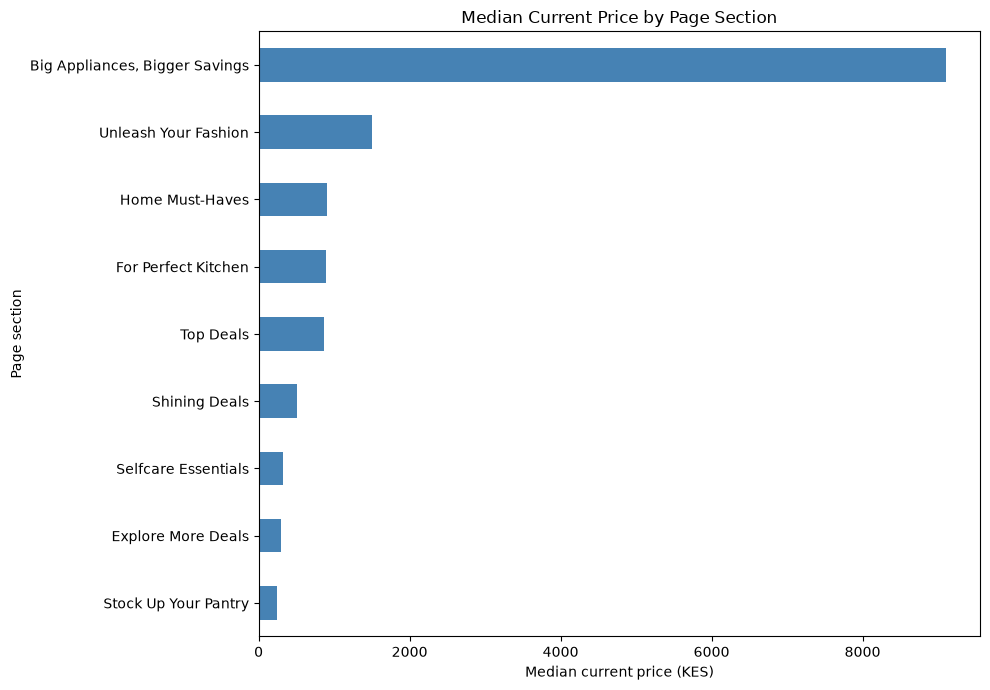

In [26]:
import matplotlib.pyplot as plt

# Find the median current price for each page section.
section_medians = (
    df.groupby("page_section")["current_price_kes"]
      .median()
      .sort_values()
)

# Draw horizontal bars, with the highest median at the top.
fig, ax = plt.subplots(figsize=(10, 7))
section_medians.plot(kind="barh", color="steelblue", ax=ax)
ax.set_title("Median Current Price by Page Section")
ax.set_xlabel("Median current price (KES)")
ax.set_ylabel("Page section")

# Keep all section labels visible.
plt.tight_layout()
plt.show()

## Seeing how discounts are distributed

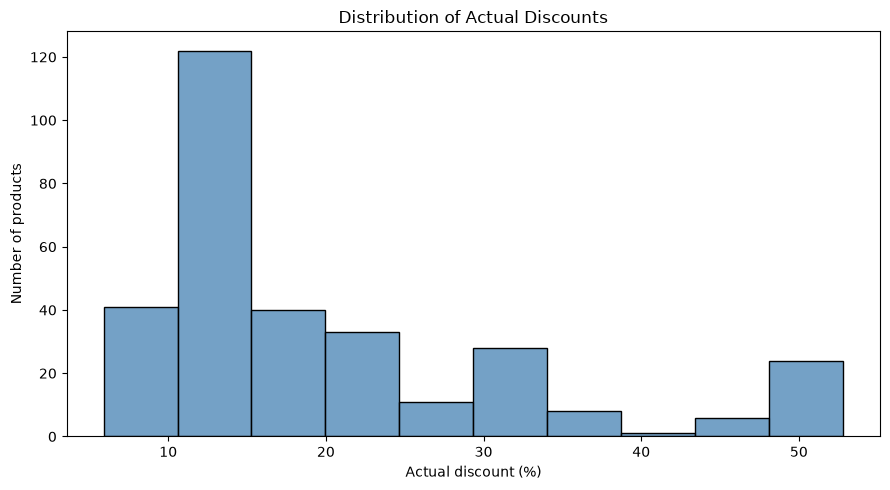

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Draw a histogram of actual discount percentages for discounted products.
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=disc, x="actual_discount_pct", bins=10, color="steelblue", ax=ax)
ax.set_title("Distribution of Actual Discounts")
ax.set_xlabel("Actual discount (%)")
ax.set_ylabel("Number of products")

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

In [28]:
import numpy as np

# Count discounted products in the same ten bins as the histogram.
counts, bin_edges = np.histogram(
    disc["actual_discount_pct"].dropna(),
    bins=10,
)

# Print the boundaries and count for the fullest bin.
peak_bin = counts.argmax()
print(
    f"Peak interval: {bin_edges[peak_bin]:.1f}%–"
    f"{bin_edges[peak_bin + 1]:.1f}% "
    f"({counts[peak_bin]} products)"
)

Peak interval: 10.6%–15.3% (122 products)


## Viewing the distribution of current prices

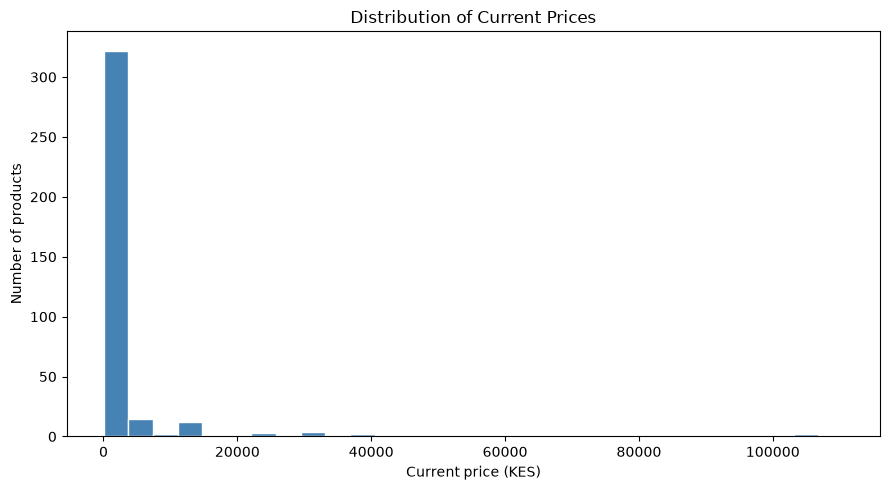

,price_kes
min,13.0
25%,240.0
50%,399.0
75%,1299.0
max,110493.0


In [30]:
import matplotlib.pyplot as plt

# Draw a 30-bin histogram of current prices.
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["current_price_kes"].dropna(), bins=30, color="steelblue", edgecolor="white")
ax.set_title("Distribution of Current Prices")
ax.set_xlabel("Current price (KES)")
ax.set_ylabel("Number of products")

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

# Summarize key points in the price distribution.
price_summary = df["current_price_kes"].describe()
display(price_summary[["min", "25%", "50%", "75%", "max"]].to_frame("price_kes"))

## Zooming in on products under KES 2,000

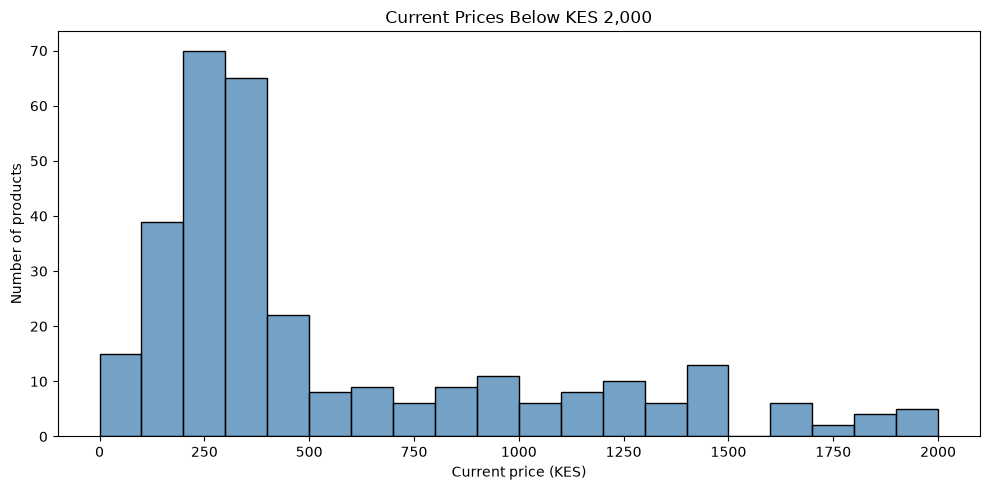

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep products priced below KES 2,000.
under_2000 = df.loc[df["current_price_kes"] < 2000]

# Draw 20 equal-width bins, each spanning KES 100.
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    data=under_2000,
    x="current_price_kes",
    bins=20,
    binrange=(0, 2000),
    color="steelblue",
    ax=ax,
)
ax.set_title("Current Prices Below KES 2,000")
ax.set_xlabel("Current price (KES)")
ax.set_ylabel("Number of products")

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

## Adding the average discount to a histogram

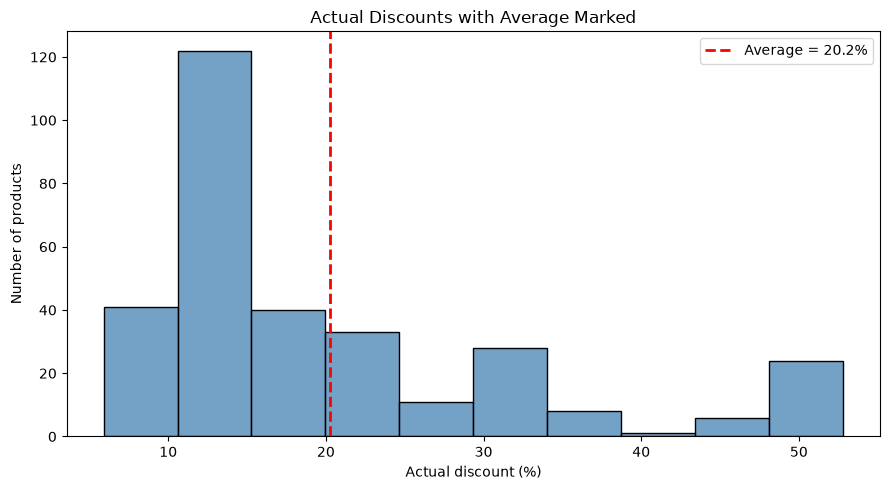

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the average actual discount for discounted products.
average_discount = disc["actual_discount_pct"].mean()

# Draw the discount histogram and mark its average with a red line.
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=disc, x="actual_discount_pct", bins=10, color="steelblue", ax=ax)
ax.axvline(
    average_discount,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Average = {average_discount:.1f}%",
)
ax.set_title("Actual Discounts with Average Marked")
ax.set_xlabel("Actual discount (%)")
ax.set_ylabel("Number of products")
ax.legend()

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

## Read the median from a box plot

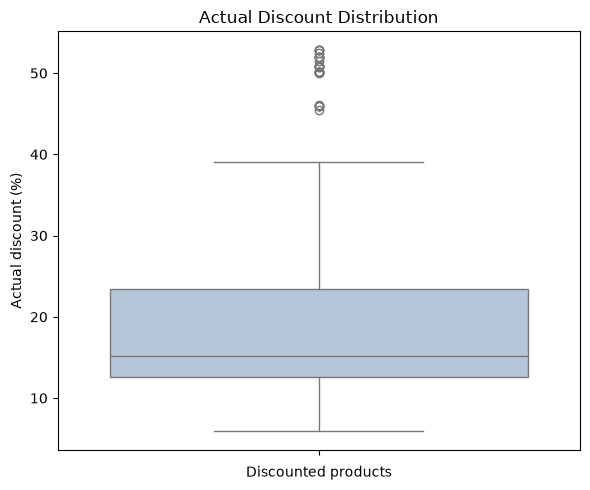

Median actual discount: 15.2%


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Draw a box plot of actual discounts for discounted products.
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=disc, y="actual_discount_pct", color="lightsteelblue", ax=ax)
ax.set_title("Actual Discount Distribution")
ax.set_xlabel("Discounted products")
ax.set_ylabel("Actual discount (%)")

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

# Calculate the exact median actual discount.
median_discount = disc["actual_discount_pct"].median()
print(f"Median actual discount: {median_discount:.1f}%")

## Compare discount spreads across departments

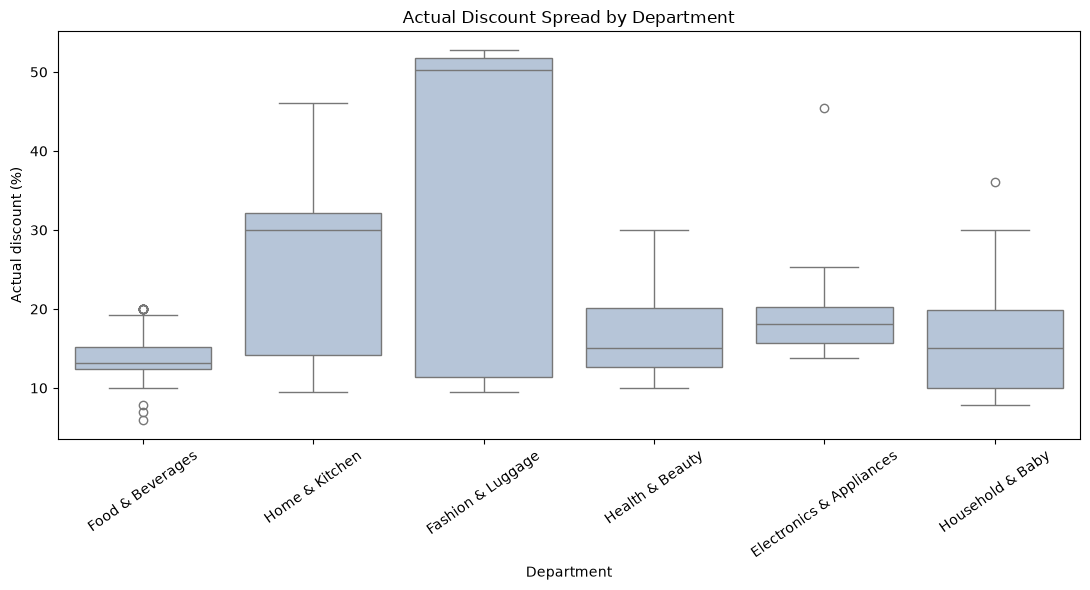

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Draw a box plot of actual discounts within each department.
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=disc,
    x="department",
    y="actual_discount_pct",
    color="lightsteelblue",
    ax=ax,
)
ax.set_title("Actual Discount Spread by Department")
ax.set_xlabel("Department")
ax.set_ylabel("Actual discount (%)")
ax.tick_params(axis="x", labelrotation=35)

# Keep the department labels readable.
plt.tight_layout()
plt.show()

## Comparing prices by delivery type

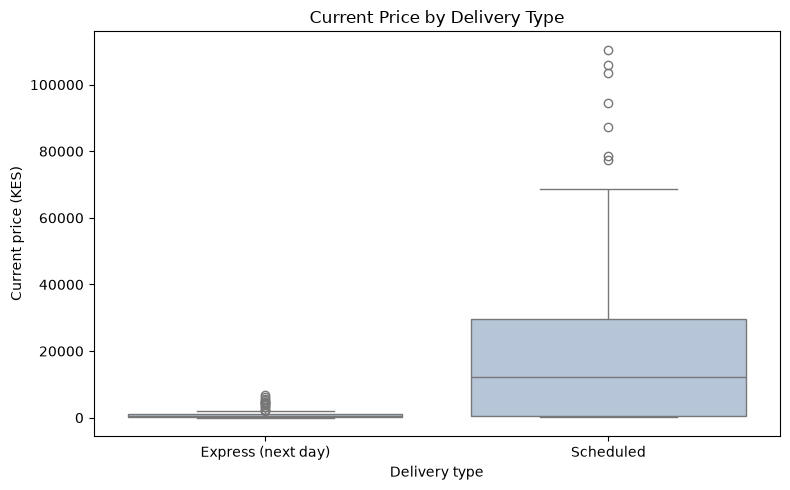

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Draw a box plot of current prices for each delivery type.
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="delivery_type",
    y="current_price_kes",
    color="lightsteelblue",
    ax=ax,
)
ax.set_title("Current Price by Delivery Type")
ax.set_xlabel("Delivery type")
ax.set_ylabel("Current price (KES)")

# Keep the chart labels from being clipped.
plt.tight_layout()
plt.show()

## Checking food-category prices for outliers

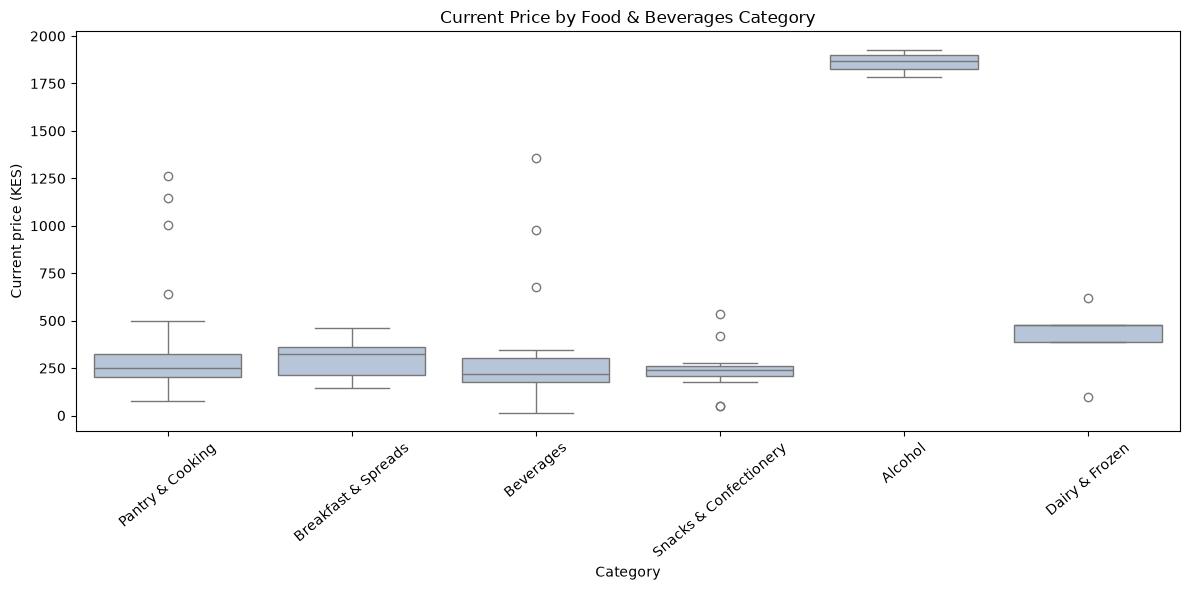

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep only Food & Beverages products.
food = df.loc[df["department"] == "Food & Beverages"].copy()

# Compare current prices across food categories and show outlier points.
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=food,
    x="category",
    y="current_price_kes",
    showfliers=True,
    color="lightsteelblue",
    ax=ax,
)
ax.set_title("Current Price by Food & Beverages Category")
ax.set_xlabel("Category")
ax.set_ylabel("Current price (KES)")
ax.tick_params(axis="x", labelrotation=40)

# Keep the category labels readable.
plt.tight_layout()
plt.show()

## Showing each department’s share

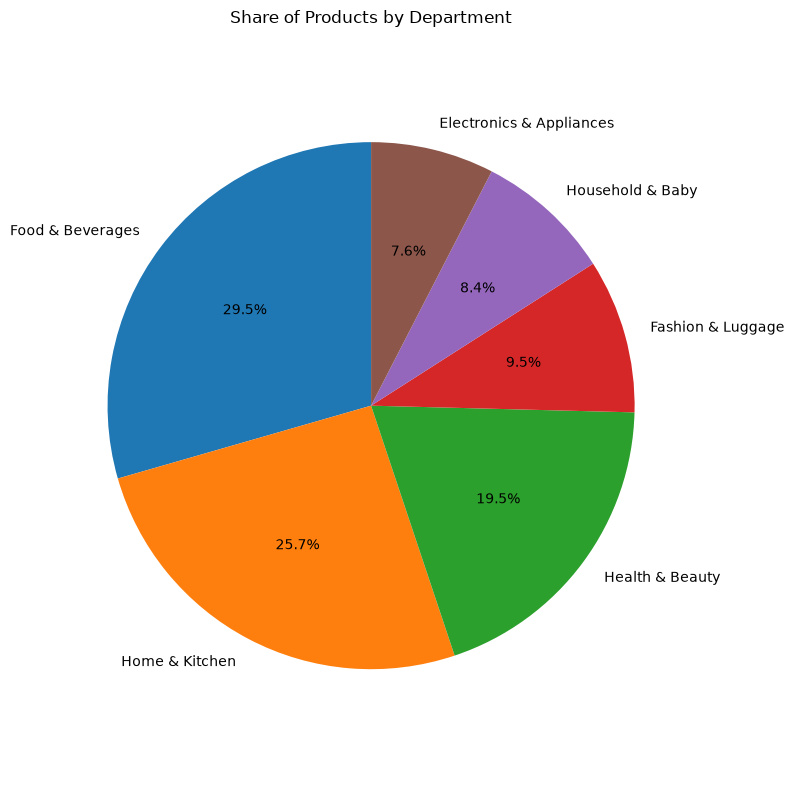

In [38]:
import matplotlib.pyplot as plt

# Count products in each department for the pie slices.
department_counts = df["department"].value_counts()

# Draw a pie chart with percentage labels.
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    department_counts,
    labels=department_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title("Share of Products by Department")
ax.axis("equal")

# Keep the pie chart circular and labels visible.
plt.tight_layout()
plt.show()

## Compare discounted and non-discounted products

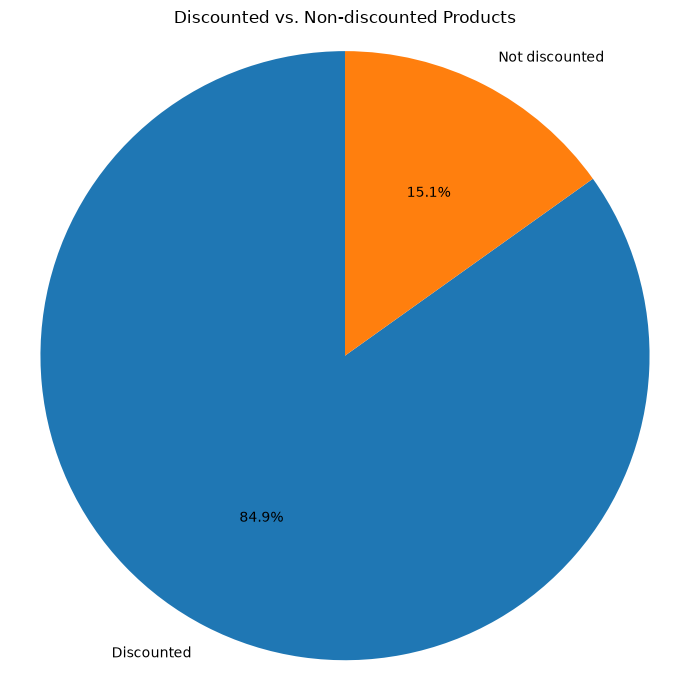

In [39]:
import matplotlib.pyplot as plt

# Count products in each discount-status group and use readable labels.
discount_counts = df["is_discounted"].value_counts().rename(
    index={True: "Discounted", False: "Not discounted"}
)

# Draw a pie chart with percentages for both groups.
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    discount_counts,
    labels=discount_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title("Discounted vs. Non-discounted Products")
ax.axis("equal")

# Keep the pie chart circular.
plt.tight_layout()
plt.show()

## Pulling out the smaller delivery slice

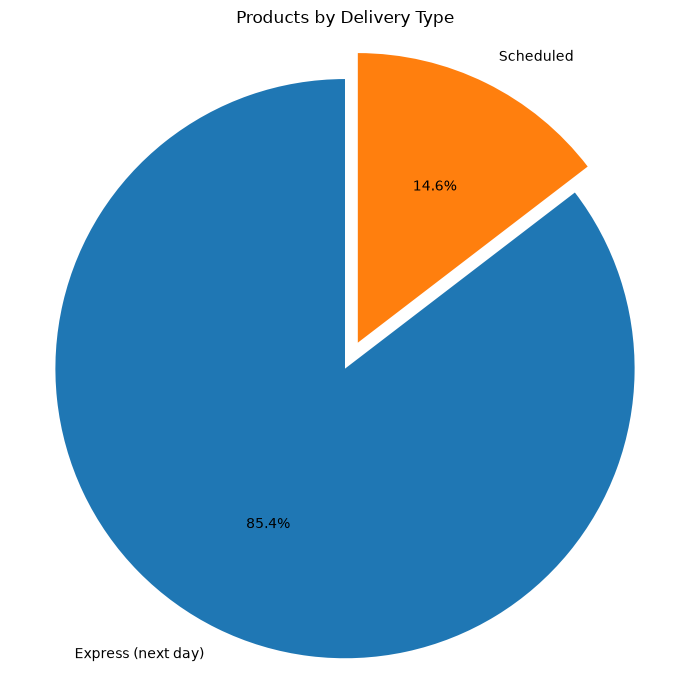

In [40]:
import matplotlib.pyplot as plt

# Count products by delivery type and find the smaller group.
delivery_counts = df["delivery_type"].value_counts()
smaller_count = delivery_counts.min()

# Pull out only the slice with the smaller count.
explode = [0.1 if count == smaller_count else 0 for count in delivery_counts]

# Draw the pie chart with percentage labels.
fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    delivery_counts,
    labels=delivery_counts.index,
    autopct="%1.1f%%",
    explode=explode,
    startangle=90,
)
ax.set_title("Products by Delivery Type")
ax.axis("equal")

# Keep the pie chart circular.
plt.tight_layout()
plt.show()

## Turn the department pie into a donut

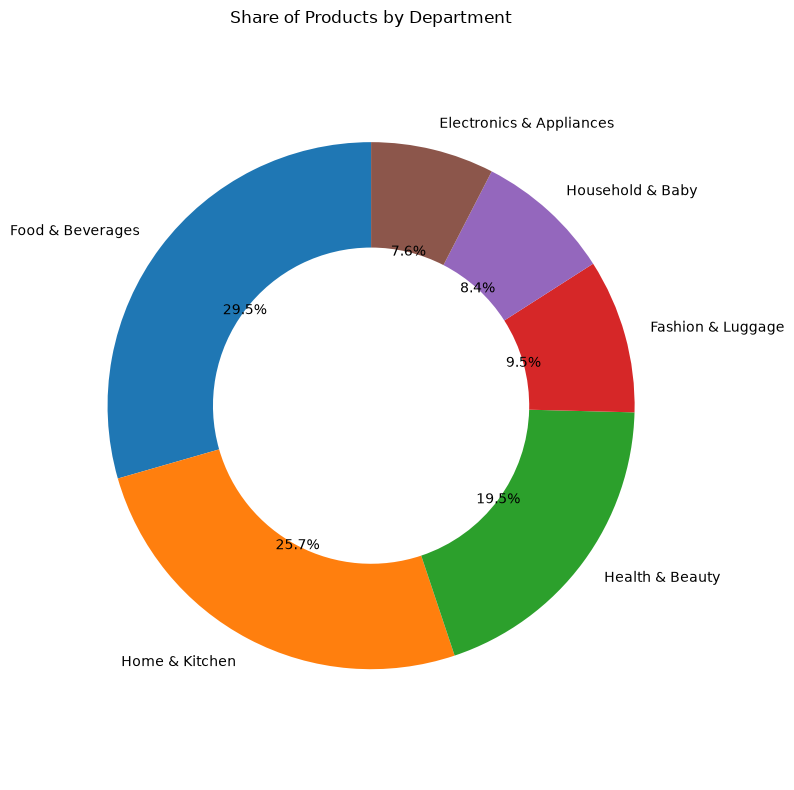

In [41]:
import matplotlib.pyplot as plt

# Count products in each department for the donut slices.
department_counts = df["department"].value_counts()

# Draw the department shares as a donut chart.
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    department_counts,
    labels=department_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4},
)
ax.set_title("Share of Products by Department")
ax.axis("equal")

# Keep the donut circular and labels visible.
plt.tight_layout()
plt.show()

## Count products by department and price band

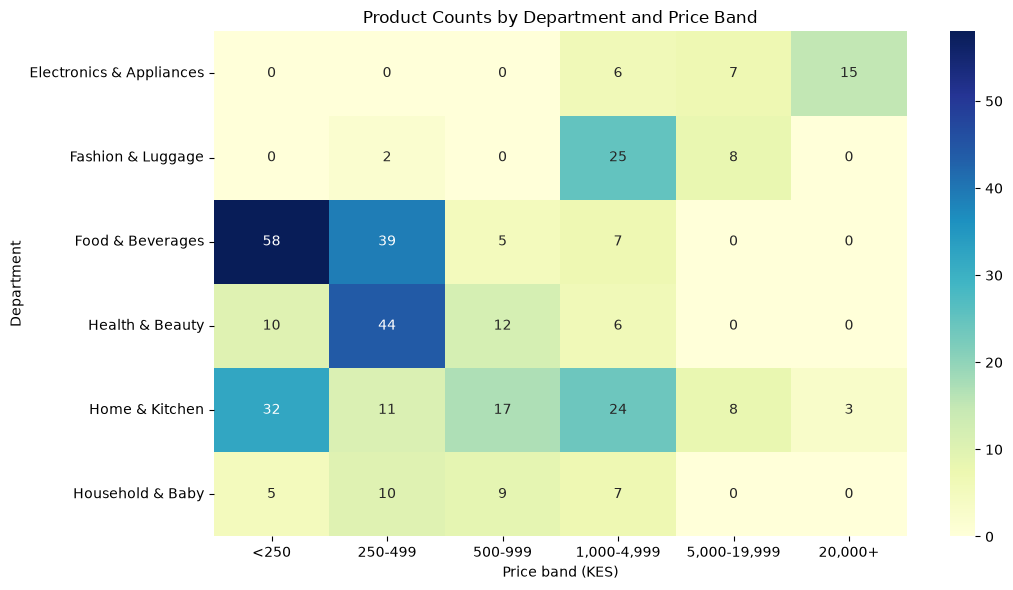

In [42]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Count products for each department and price-band combination.
table = pd.crosstab(df["department"], df["price_band"])

# Keep price bands in their natural low-to-high order.
price_band_order = ["<250", "250-499", "500-999", "1,000-4,999", "5,000-19,999", "20,000+"]
table = table.reindex(columns=[band for band in price_band_order if band in table.columns])

# Draw and annotate the count heatmap.
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(table, annot=True, fmt="d", cmap="YlGnBu", ax=ax)
ax.set_title("Product Counts by Department and Price Band")
ax.set_xlabel("Price band (KES)")
ax.set_ylabel("Department")

# Keep all labels and cell counts visible.
plt.tight_layout()
plt.show()

## Heatmap of department and delivery type

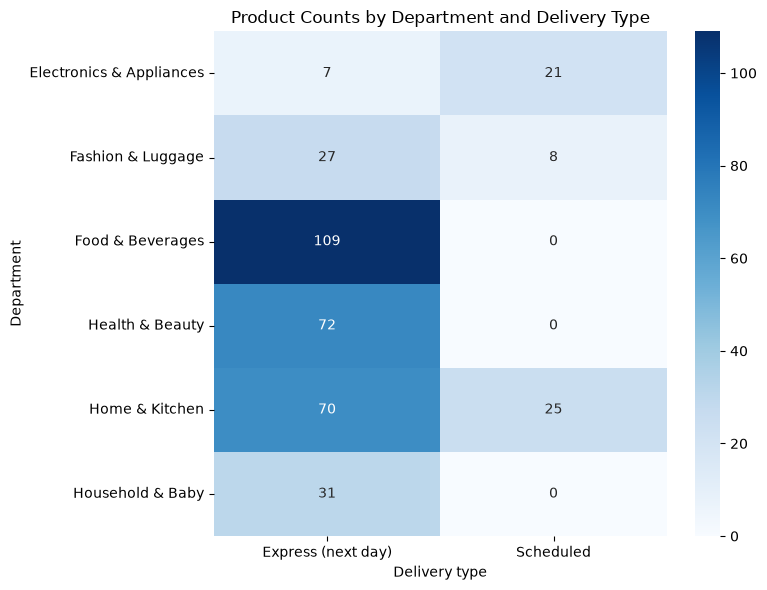

In [43]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Count products for each department and delivery-type combination.
delivery_table = pd.crosstab(df["department"], df["delivery_type"])

# Draw a blue heatmap with the count printed in every cell.
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    delivery_table,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax,
)
ax.set_title("Product Counts by Department and Delivery Type")
ax.set_xlabel("Delivery type")
ax.set_ylabel("Department")

# Keep the labels and count annotations readable.
plt.tight_layout()
plt.show()

## Heatmap of average discounts by department and delivery type

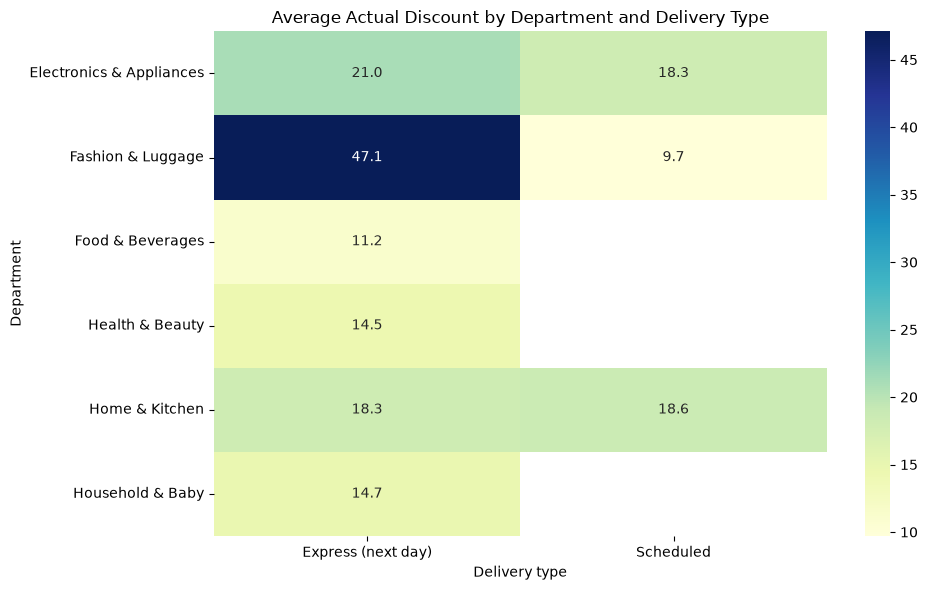

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the mean actual discount for each department and delivery type.
discount_pivot = (
    df.pivot_table(
        index="department",
        columns="delivery_type",
        values="actual_discount_pct",
        aggfunc="mean",
    )
    .round(1)
)

# Draw the average discounts as an annotated heatmap.
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    discount_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    ax=ax,
)
ax.set_title("Average Actual Discount by Department and Delivery Type")
ax.set_xlabel("Delivery type")
ax.set_ylabel("Department")

# Keep the labels and values readable.
plt.tight_layout()
plt.show()

## Correlation heatmap

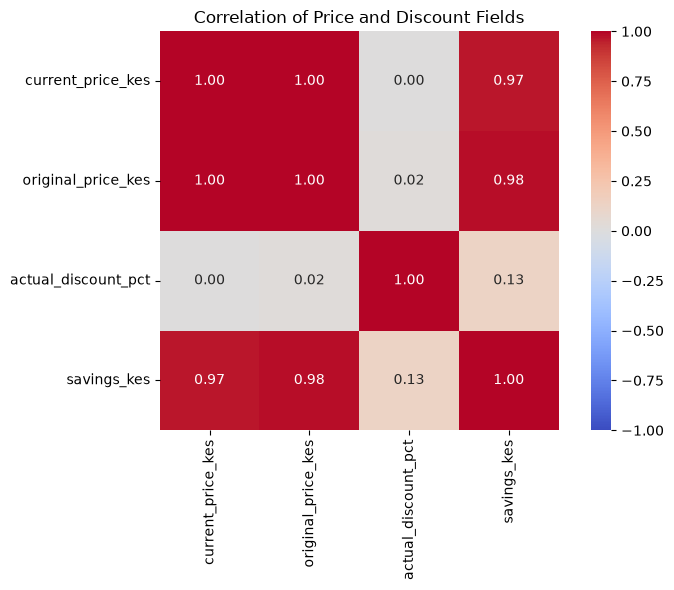

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the four price and discount columns for comparison.
cols = [
    "current_price_kes",
    "original_price_kes",
    "actual_discount_pct",
    "savings_kes",
]
correlations = df[cols].corr()

# Draw the correlations on a scale from -1 to 1.
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title("Correlation of Price and Discount Fields")

# Keep the column labels readable.
plt.tight_layout()
plt.show()

## Compare original and current prices

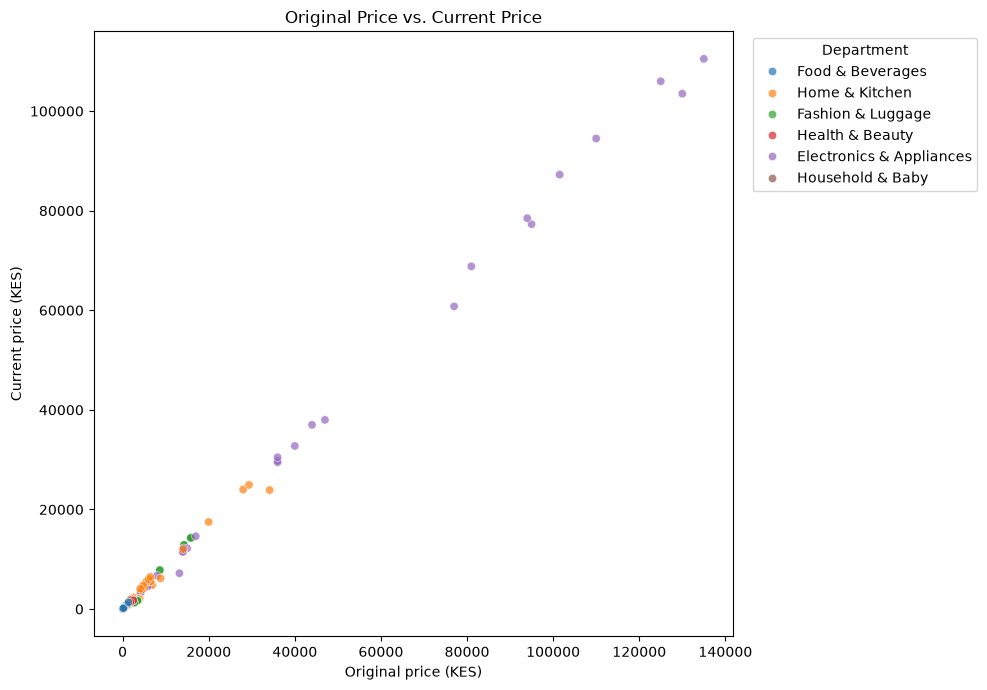

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

# Find a shared maximum so both price axes use the same scale.
max_price = df[["original_price_kes", "current_price_kes"]].max().max()

# Plot original price against current price, colored by department.
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(
    data=df,
    x="original_price_kes",
    y="current_price_kes",
    hue="department",
    alpha=0.7,
    ax=ax,
)
ax.set_title("Original Price vs. Current Price")
ax.set_xlabel("Original price (KES)")
ax.set_ylabel("Current price (KES)")
ax.legend(title="Department", bbox_to_anchor=(1.02, 1), loc="upper left")

# Make room for the department legend.
plt.tight_layout()
plt.show()

## Putting two charts side by side

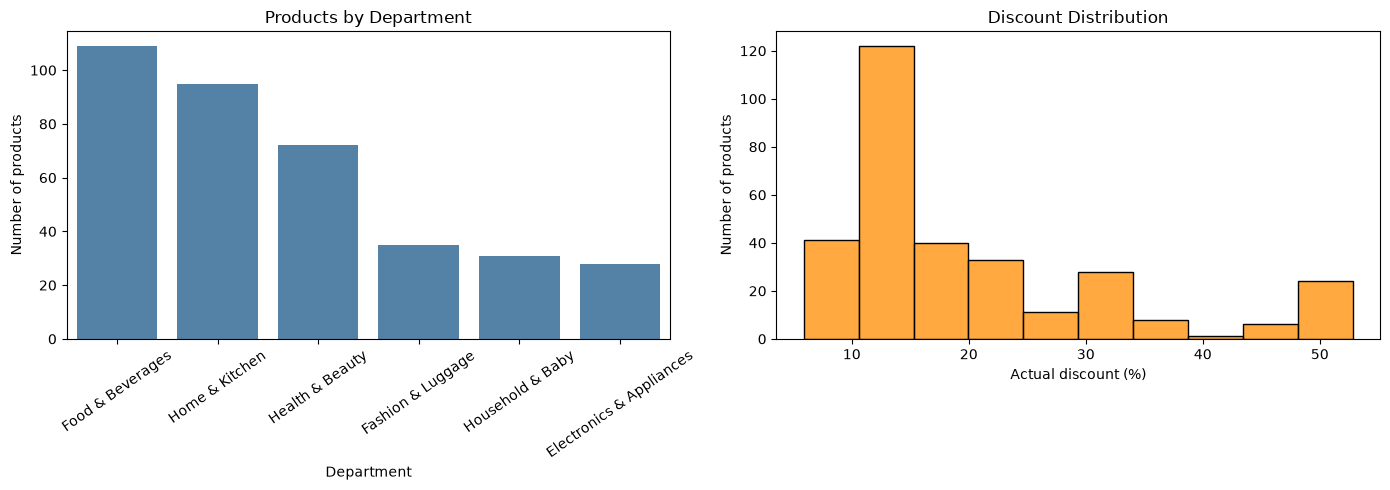

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Order departments from most products to fewest.
department_order = df["department"].value_counts().index

# Create a side-by-side layout for the two charts.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Show product counts by department in the first panel.
sns.countplot(data=df, x="department", order=department_order, color="steelblue", ax=axes[0])
axes[0].set_title("Products by Department")
axes[0].set_xlabel("Department")
axes[0].set_ylabel("Number of products")
axes[0].tick_params(axis="x", labelrotation=35)

# Show discount percentages for discounted products in the second panel.
sns.histplot(data=disc, x="actual_discount_pct", bins=10, color="darkorange", ax=axes[1])
axes[1].set_title("Discount Distribution")
axes[1].set_xlabel("Actual discount (%)")
axes[1].set_ylabel("Number of products")

# Adjust spacing so both panels and labels fit.
plt.tight_layout()
plt.show()

## Building and save a 2 × 2 chart grid

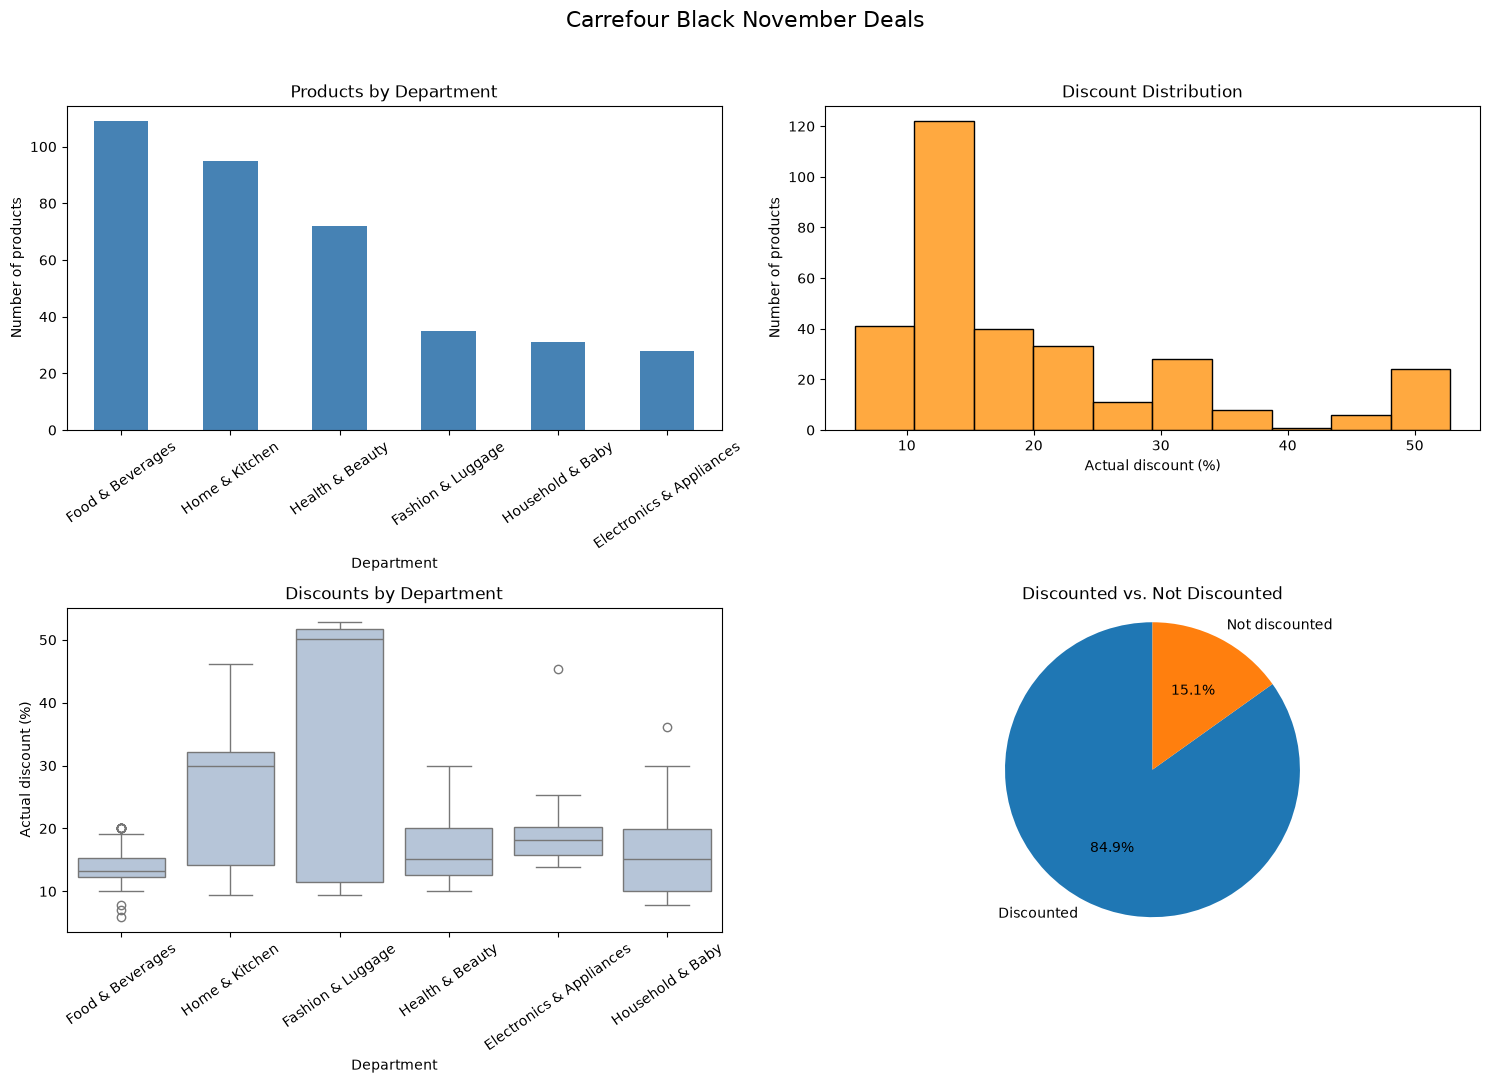

Saved to: C:\Users\User\Desktop\KERONGO'`S SHIT\carrefour_black_november\outputs\figures\deals_dashboard.png


In [52]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare counts and labels for the dashboard charts.
department_counts = df["department"].value_counts()
discount_counts = df["is_discounted"].value_counts().rename(
    index={True: "Discounted", False: "Not discounted"}
)

# Create a 2 × 2 layout for the four charts.
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Top-left: compare product counts by department.
department_counts.plot(kind="bar", color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Products by Department")
axes[0, 0].set_xlabel("Department")
axes[0, 0].set_ylabel("Number of products")
axes[0, 0].tick_params(axis="x", labelrotation=35)

# Top-right: show discounts for discounted products.
sns.histplot(data=disc, x="actual_discount_pct", bins=10, color="darkorange", ax=axes[0, 1])
axes[0, 1].set_title("Discount Distribution")
axes[0, 1].set_xlabel("Actual discount (%)")
axes[0, 1].set_ylabel("Number of products")

# Bottom-left: compare discount distributions by department.
sns.boxplot(data=disc, x="department", y="actual_discount_pct", color="lightsteelblue", ax=axes[1, 0])
axes[1, 0].set_title("Discounts by Department")
axes[1, 0].set_xlabel("Department")
axes[1, 0].set_ylabel("Actual discount (%)")
axes[1, 0].tick_params(axis="x", labelrotation=35)

# Bottom-right: show the share of discounted and non-discounted products.
axes[1, 1].pie(
    discount_counts,
    labels=discount_counts.index,
    autopct="%1.1f%%",
    startangle=90,
)
axes[1, 1].set_title("Discounted vs. Not Discounted")
axes[1, 1].axis("equal")

# Add a figure title and save the finished dashboard as a PNG.
fig.suptitle("Carrefour Black November Deals", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
output_path = Path("../outputs/figures/deals_dashboard.png")
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved to:", output_path.resolve())

In [3]:
from pathlib import Path

# Check that the renamed CSV is reachable from the notebook.
csv_path = Path("../data/raw/carrefour_ke_black_november_deals.csv")
print("CSV found:", csv_path.exists())

CSV found: True


In [4]:
from pathlib import Path
import pandas as pd

# Load the renamed CSV from the project's data/raw folder.
csv_path = Path("../data/raw/carrefour_ke_black_november_deals.csv")
df = pd.read_csv(csv_path)

# Confirm the dataset loaded with the expected dimensions.
print("Rows, columns:", df.shape)

Rows, columns: (370, 29)
